# Tareita 1

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

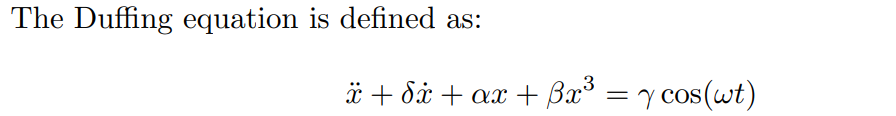

## Runge-Kutta de 4°

In [ ]:
def rk4_step(f, t, y, h):
    k1 = f(t, y)
    k2 = f(t + h/2, y + h/2 * np.array(k1))
    k3 = f(t + h/2, y + h/2 * np.array(k2))
    k4 = f(t + h, y + h * np.array(k3))
    return y + h/6 * (np.array(k1) + 2*np.array(k2) + 2*np.array(k3) + np.array(k4))

In [ ]:
def solve_ivp_rk4(f, t_span, y0, t_eval):
    t0, tf = t_span
    y = np.array(y0)
    sol_t = [t0]
    sol_y = [y]
    h = (tf - t0) / len(t_eval)

    for t in t_eval[1:]:
        y = rk4_step(f, sol_t[-1], sol_y[-1], h)
        sol_t.append(t)
        sol_y.append(y)

    return np.array(sol_t), np.array(sol_y).T

## Duffing

In [ ]:
# Params
delta = 0.2  # Amortiguamiento
alpha = -1   # Rigidez lineal
beta = 1     # Rigidez no lineal
gamma = 0.3  # Amplitud de la fuerza externa
omega = 1.2  # Frecuencia de la fuerza externa

In [ ]:
def duffing(t, y):
    x, v = y
    dxdt = v
    dvdt = -delta * v - alpha * x - beta * x**3 + gamma * np.cos(omega * t)
    return [dxdt, dvdt]


In [ ]:
#initial cond
t_span = (0, 3000)
t_eval = np.linspace(0, 3000, 10000)
y0 = [0.1, 0.1]

In [ ]:
t_rk4, y_rk4 = solve_ivp_rk4(duffing, t_span, y0, t_eval)

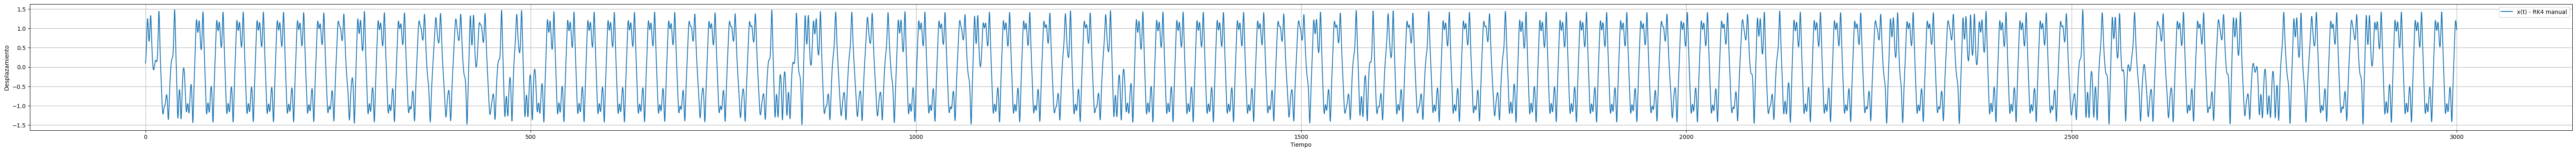

In [ ]:
plt.figure(figsize=(80, 4))
plt.plot(t_rk4, y_rk4[0], label='x(t) - RK4 manual')
plt.xlabel('Tiempo')
plt.ylabel('Desplazamiento')
plt.legend()
plt.grid()
plt.show()

##Liapunov exponent

In [ ]:
def lyapunov_exp(system, y0, t_span, t_eval):
    epsilon = 1e-8  # Pequeña perturbación
    y1 = np.array(y0) + epsilon  # Estado perturbado

    t_rk4_1, sol_1 = solve_ivp_rk4(system, t_span, y0, t_eval)
    t_rk4_2, sol_2 = solve_ivp_rk4(system, t_span, y1, t_eval)

    d_0 = np.linalg.norm(np.array(y1) - np.array(y0)) + 1e-10  # Evitar división por cero
    d_t = np.linalg.norm(sol_2 - sol_1, axis=0) + 1e-10  # Evitar valores muy pequeños

    lyap_exp = np.mean(np.log(d_t / d_0)) / (t_eval[-1] - t_eval[0])
    return lyap_exp

In [ ]:
lyap = lyapunov_exp(duffing, y0, t_span, t_eval)
print(f"Exponente de Lyapunov estimado: {lyap}")

Exponente de Lyapunov estimado: 0.005636937339260941


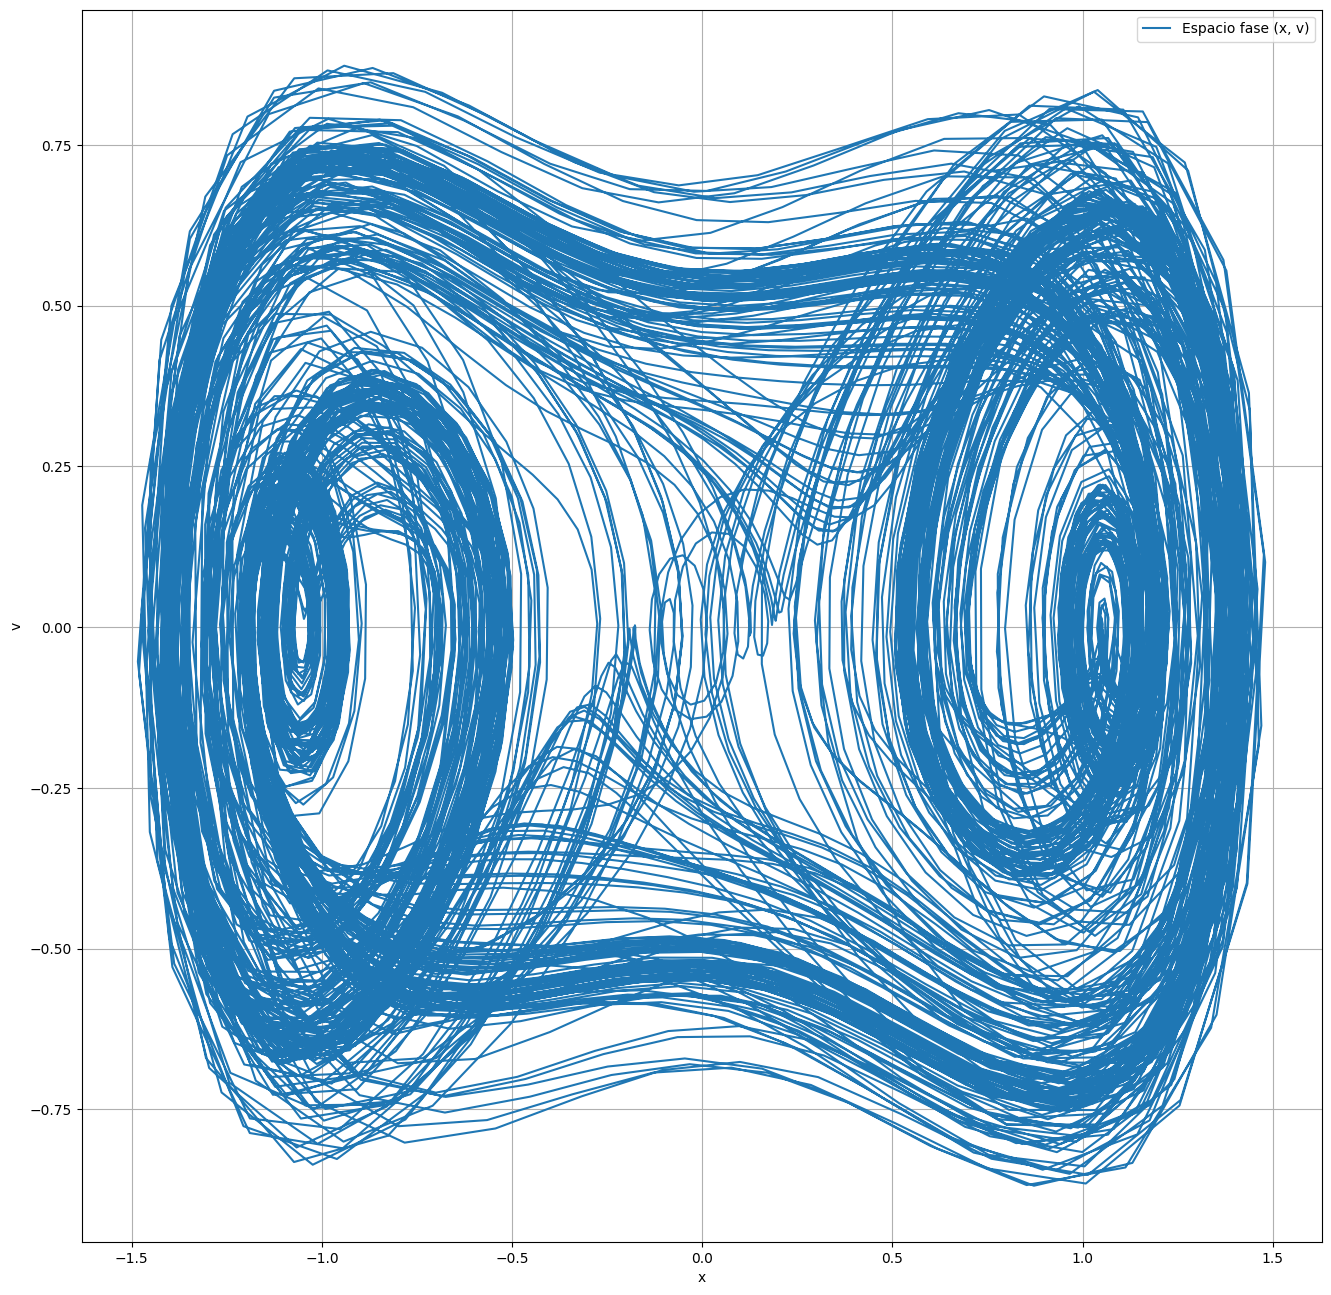

In [ ]:
plt.figure(figsize=(16, 16))
plt.plot(y_rk4[0], y_rk4[1], label='Espacio fase (x, v)')
plt.xlabel('x')
plt.ylabel('v')
plt.legend()
plt.grid()
plt.show()